# Fitting the spectrum of the Sun

This example fits an observed spectrum with a grid of model spectra and
compares the fitted parameters with the known values for the Sun. The
spectrum is the solar irradiance atlas of Kurucz (2005; Kurucz 2006,
[arXiv:astro-ph/0605029](https://arxiv.org/abs/astro-ph/0605029)), which is
included with StarKit. The grid is the test grid
`phoenix_t4000_10000_w3000_9000_r3000.h5` in this directory.

The fit uses MultiNest, which needs the pymultinest package and the MultiNest
library (see [Installation](../installation.rst)), and takes about a minute. The
figures need matplotlib and corner (`pip install matplotlib corner`).

In [1]:
import logging
import time
import warnings
from importlib.resources import files

import corner
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.table import Table

from starkit import assemble_model
from starkit.fitkit.likelihoods import SpectralChi2Likelihood
from starkit.fitkit.multinest import MultiNest
from starkit.fitkit.priors import UniformPrior
from starkit.fix_spectrum1d import SKSpectrum1D
from starkit.gridkit import load_grid

logging.getLogger('starkit').setLevel(logging.WARNING)
# The normalization warns about every full-rank polynomial fit (BUGS.md).
warnings.filterwarnings('ignore', message='The fit may be poorly conditioned')
# The flux unit label of the grid, erg/s/angstrom, has several slashes.
warnings.filterwarnings('ignore', message='.*contains multiple slashes')

## The solar spectrum

The atlas is made from Fourier transform spectra of the Sun taken at Kitt
Peak, with the telluric lines divided out, and calibrated to the solar
irradiance of Thuillier et al. (2004). Its wavelengths are vacuum wavelengths
in the rest frame of the Sun and include the gravitational redshift of the
solar spectrum, 0.64 km/s. The file
`sun_kurucz2005_r1500.fits` in the `starkit/data` directory holds the
irradiance at Earth in W m$^{-2}$ nm$^{-1}$ from 3010 to 9000 Å, smoothed to a
resolving power $R = \lambda / \Delta\lambda = 1500$ ($\Delta\lambda$ is the
FWHM of a Gaussian line profile) and sampled on the wavelengths of the grid.
The name of the grid says $R = 3000$, but its spectra have $R = 1500$ (see
`BUGS.md`), and an observed spectrum must not have a higher resolving power
than the grid it is fitted with. The script `make_solar_spectrum.py` in this
directory makes the file from the atlas.

In [2]:
sun = Table.read(files('starkit') / 'data' / 'sun_kurucz2005_r1500.fits')
print(sun.meta['REFERENC'])
sun[:3]

Kurucz, R. L. 2006, arXiv:astro-ph/0605029


WAVELENGTH,FLUX
Angstrom,W / (nm m2)
float64,float64
3010.0166852005304,0.45825735035046533
3010.267530376032,0.48909447220077834
3010.5183964561693,0.5240649017823544


The fit uses 3800 to 8950 Å. The upper limit keeps the model, shifted by up
to 50 km/s, inside the 9000 Å end of the grid.

The atlas gives no uncertainty for each flux point, so this example assumes
a signal-to-noise ratio of 100 per point: the uncertainty is 1% of the flux.
For your own spectrum, give the measured uncertainty of each flux point
instead. The widths of the posteriors below scale with the uncertainties.

In [3]:
in_range = (sun['WAVELENGTH'] > 3800) & (sun['WAVELENGTH'] < 8950)
wavelength = sun['WAVELENGTH'][in_range].quantity
flux = sun['FLUX'][in_range].quantity
uncertainty = flux.value / 100.  # assumed signal-to-noise ratio of 100
spectrum = SKSpectrum1D.from_array(wavelength=wavelength, flux=flux,
                                   uncertainty=uncertainty)
print(f'{len(wavelength)} points from {wavelength[0]:.1f} to '
      f'{wavelength[-1]:.1f}')

10280 points from 3800.1 Angstrom to 8949.6 Angstrom


## The model and the likelihood

`assemble_model` builds the model for the observed spectrum: it interpolates
the grid at $T_\mathrm{eff}$, $\log g$ and [M/H], shifts the spectrum by the
radial velocity `vrad` (km/s), interpolates it onto the observed wavelengths,
and multiplies it by the polynomial in wavelength of degree 10
(`normalize_npol=10`) that best matches the observed spectrum. The polynomial
takes up the flux scale, since the grid holds the flux at the stellar surface
and the atlas the irradiance at Earth, and any error in the flux calibration.
It also takes up most of the slope of the continuum, so the fit uses mainly
the absorption lines. `SpectralChi2Likelihood` turns the model into the
log-likelihood $-\chi^2/2$.

In [4]:
grid = load_grid('phoenix_t4000_10000_w3000_9000_r3000.h5',
                 wavelength_type='vacuum')
model = assemble_model(grid, spectrum=spectrum, vrad=0., normalize_npol=10)
likelihood = model | SpectralChi2Likelihood(spectrum)
free_parameters = [name for name in likelihood.param_names
                   if not getattr(likelihood, name).fixed]
free_parameters

['teff_0', 'logg_0', 'mh_0', 'vrad_1']

## The fit

MultiNest needs a prior for each free parameter, in the order of
`free_parameters`. The priors are uniform: over the grid for
$T_\mathrm{eff}$ (4000 to 10000 K), $\log g$ (3.0 to 5.0) and [M/H] (-1.0 to
0.0), and from -50 to 50 km/s for the radial velocity. The solar [M/H] of 0.0
is at the upper edge of the grid. With the seed, running the notebook from
the top reproduces the outputs below, apart from the run time.

In [5]:
priors = grid.get_grid_uniform_priors() + [UniformPrior(-50., 50.)]
fitter = MultiNest(likelihood, priors)
start = time.time()
result = fitter.run(seed=1)
print(f'{time.time() - start:.0f} s')

 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    4
 *****************************************************


 ln(ev)=  -22938.602688210340      +/-  0.23927456411051992     
 Total Likelihood Evaluations:        19290
 Sampling finished. Exiting MultiNest
54 s


## Results

The table gives the median of each posterior, the distances from the median
to the limits of the central 68% of the posterior, and the solar values:
$T_\mathrm{eff}$ = 5772 K and $\log g$ = 4.44 from the nominal solar values
of IAU 2015 Resolution B3 (Prša et al. 2016, AJ 152, 41), [M/H] = 0.0, and a
radial velocity of 0.64 km/s, the gravitational redshift that the atlas
includes.

In [6]:
solar = {'teff_0': 5772., 'logg_0': 4.44, 'mh_0': 0.0, 'vrad_1': 0.64}
labels = {'teff_0': 'Teff (K)', 'logg_0': 'log g', 'mh_0': '[M/H]',
          'vrad_1': 'v_rad (km/s)'}
digits = {'teff_0': 0, 'logg_0': 3, 'mh_0': 3, 'vrad_1': 2}
limits = result.calculate_sigmas(1)
rows = {}
for name, label in labels.items():
    median = result.median[name]
    lower, upper = limits[name]
    n = digits[name]
    rows[label] = {'median': f'{median:.{n}f}',
                   '68% interval': f'+{upper - median:.{n}f} -{median - lower:.{n}f}',
                   'Sun': f'{solar[name]:.{n}f}',
                   'median - Sun': f'{median - solar[name]:+.{n}f}'}
pd.DataFrame(rows).T

,median,68% interval,Sun,median - Sun
Teff (K),5805,+1 -1,5772,+33
log g,4.343,+0.003 -0.003,4.440,-0.097
[M/H],-0.129,+0.003 -0.003,0.000,-0.129
v_rad (km/s),-0.78,+0.21 -0.19,0.64,-1.42


The model at the medians of the posteriors, and its $\chi^2$ per flux
point:

In [7]:
for name in free_parameters:
    setattr(model, name, result.median[name])
model_wavelength, model_flux = model()
observed_flux = flux.value
chi2 = np.sum(((observed_flux - model_flux) / uncertainty)**2)
print(f'chi2 per flux point: {chi2 / observed_flux.size:.2f}')
difference = 100 * (observed_flux - model_flux) / observed_flux
blue = wavelength.value < 4500
for part, name in [(blue, 'below'), (~blue, 'above')]:
    rms = np.sqrt(np.mean(difference[part]**2))
    print(f'rms difference {name} 4500 Angstrom: {rms:.2f}%')

chi2 per flux point: 4.46
rms difference below 4500 Angstrom: 3.66%
rms difference above 4500 Angstrom: 1.50%


The fitted $T_\mathrm{eff}$ is 33 K above the solar value, $\log g$ is 0.097
lower and [M/H] is 0.129 dex lower. The radial velocity of -0.78 km/s is
1.42 km/s below the gravitational redshift, a difference small compared with
the 25 km/s spacing of the grid wavelengths.

These differences are many times the 68% intervals of the posteriors (1 K in
$T_\mathrm{eff}$, 0.003 in $\log g$ and in [M/H], 0.2 km/s in the radial
velocity). The posteriors assume that
the model matches the spectrum to within the assumed uncertainty of 1%, and
it does not: the $\chi^2$ per flux point is 4.46, and the model and the
spectrum differ by 3.66% rms below 4500 Å and 1.50% above. The middle panel
of the figure below shows the differences; they are largest below 4500 Å, in
the Mg b lines at 5165 to 5185 Å, in the Ca II lines near 8500 Å, and at 6710 Å,
where the model has an absorption line that is nearly absent from the atlas. The posterior
widths therefore understate the errors of the fitted parameters. For this
grid at $R = 1500$, the differences from the solar values are a better
indication of the error of a fit to a star like the Sun.


The observed spectrum with the model, their difference, and three regions
in detail:

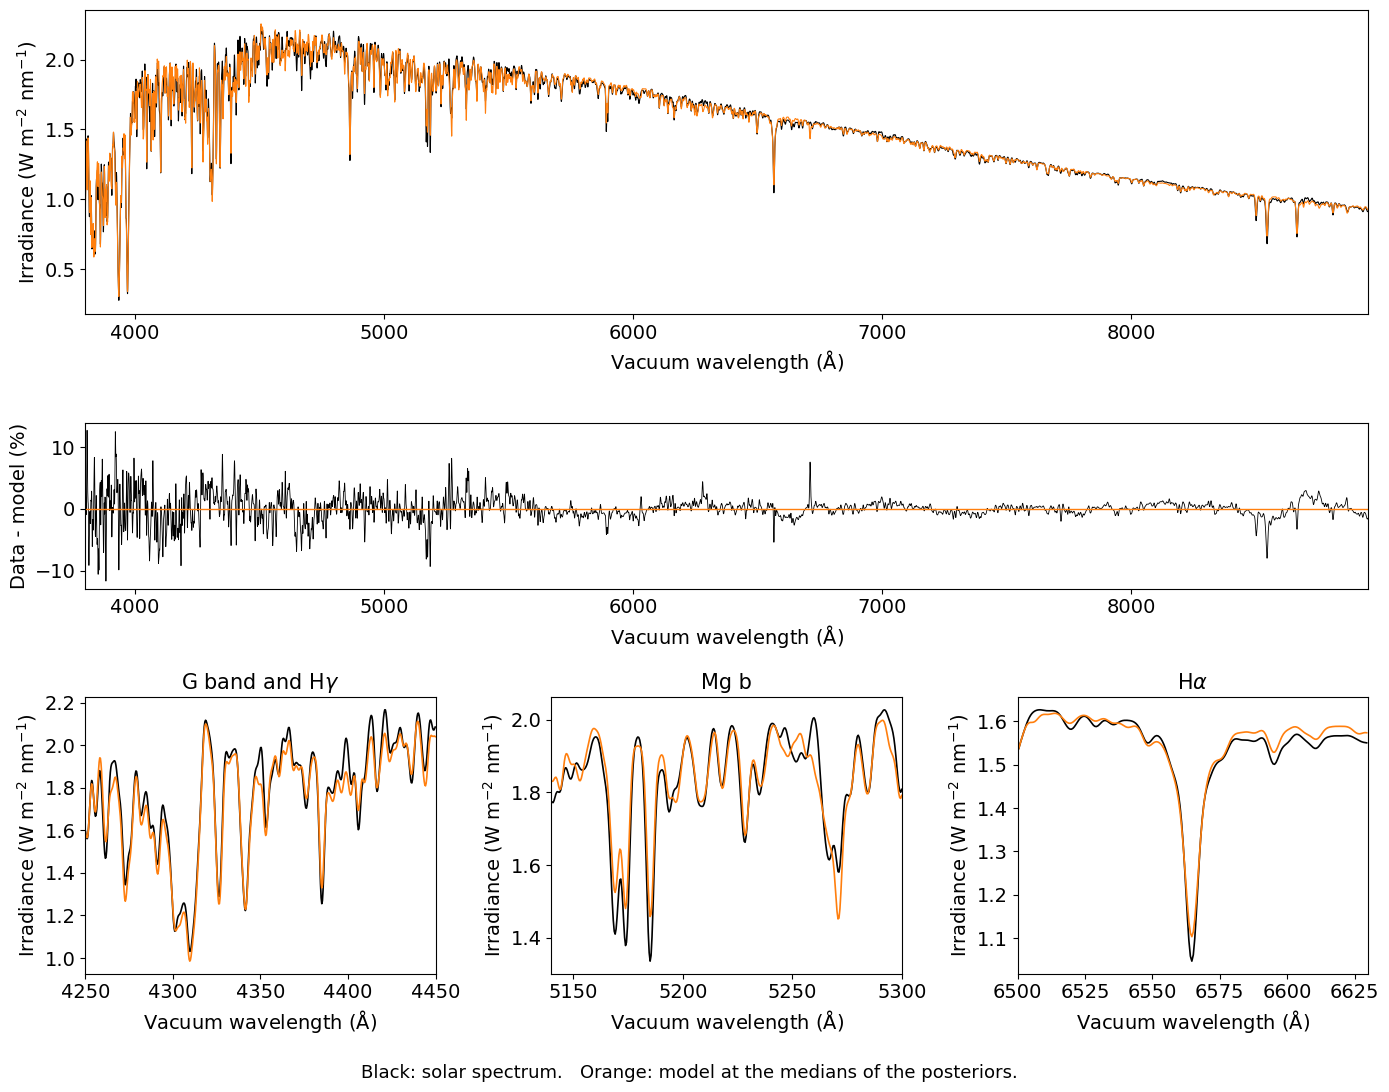

In [8]:
FONT_KW = {'legend.fontsize': 13, 'font.size': 14, 'axes.titlesize': 15,
           'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14,
           'figure.titlesize': 16}
plt.rcParams.update(FONT_KW)
w = wavelength.value
flux_label = r'Irradiance (W m$^{-2}$ nm$^{-1}$)'
wavelength_label = r'Vacuum wavelength ($\mathrm{\AA}$)'

fig = plt.figure(figsize=(14, 11))
grid_spec = fig.add_gridspec(3, 3, height_ratios=[2.2, 1.2, 2])
ax = fig.add_subplot(grid_spec[0, :])
ax.plot(w, observed_flux, color='black', lw=0.8)
ax.plot(w, model_flux, color='tab:orange', lw=0.8)
ax.set_xlim(w[0], w[-1])
ax.set_xlabel(wavelength_label)
ax.set_ylabel(flux_label)

ax = fig.add_subplot(grid_spec[1, :])
ax.plot(w, 100 * (observed_flux - model_flux) / observed_flux, color='black',
        lw=0.6)
ax.axhline(0, color='tab:orange', lw=1)
ax.set_xlim(w[0], w[-1])
ax.set_xlabel(wavelength_label)
ax.set_ylabel('Data - model (%)')

regions = [(4250, 4450, r'G band and H$\gamma$'), (5140, 5300, 'Mg b'),
           (6500, 6630, r'H$\alpha$')]
for i, (low, high, title) in enumerate(regions):
    ax = fig.add_subplot(grid_spec[2, i])
    shown = (w > low) & (w < high)
    ax.plot(w[shown], observed_flux[shown], color='black', lw=1.2)
    ax.plot(w[shown], model_flux[shown], color='tab:orange', lw=1.2)
    ax.set_xlim(low, high)
    ax.set_title(title)
    ax.set_xlabel(wavelength_label)
    ax.set_ylabel(flux_label)

fig.text(0.5, 0.01, 'Black: solar spectrum.   Orange: model at the medians '
         'of the posteriors.', ha='center', fontsize=13)
fig.tight_layout(rect=(0, 0.03, 1, 1))

The posteriors in a corner plot. The solar values lie outside the plotted
range of every parameter (see the table above), so they are not drawn.

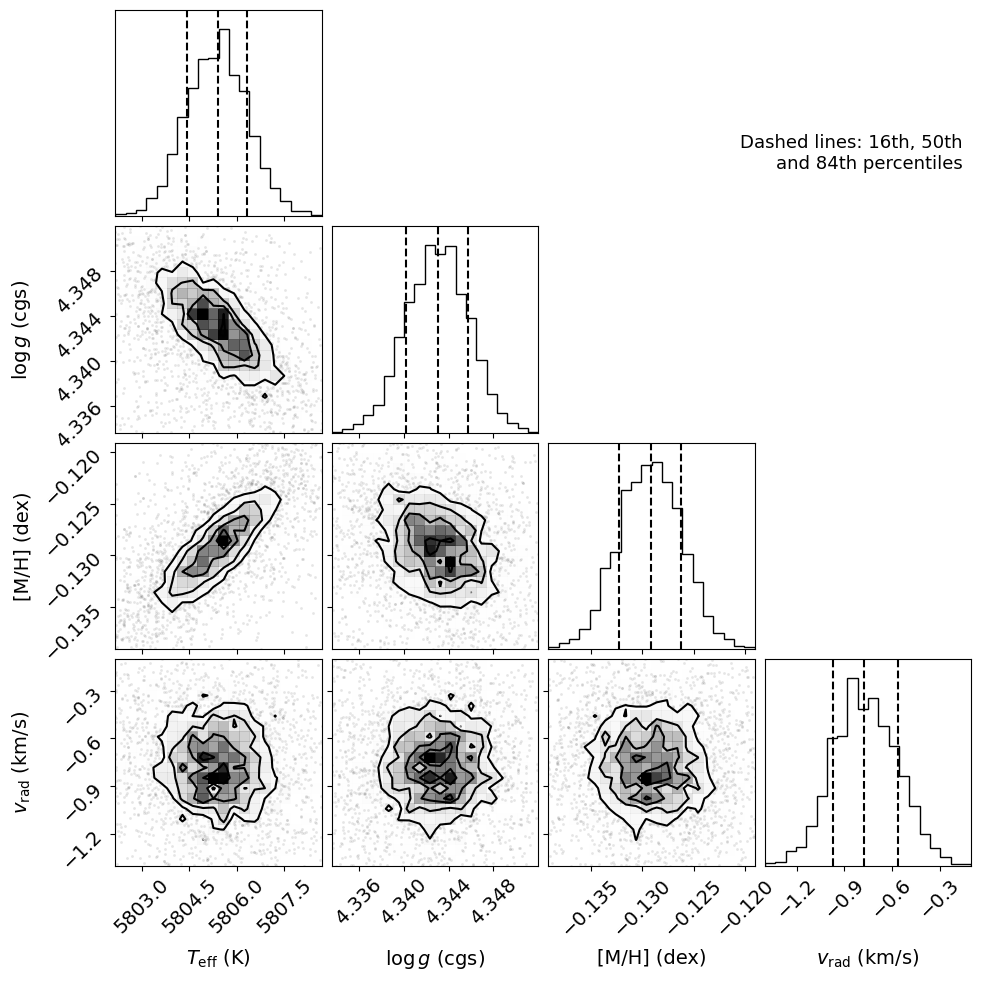

In [9]:
axis_labels = [r'$T_\mathrm{eff}$ (K)', r'$\log g$ (cgs)', '[M/H] (dex)',
               r'$v_\mathrm{rad}$ (km/s)']
fig = plt.figure(figsize=(10, 10))
corner.corner(result.posterior_data[free_parameters].to_numpy(),
              weights=result.posterior_data['weights'].to_numpy(),
              labels=axis_labels, range=[0.999] * len(free_parameters),
              quantiles=[0.16, 0.5, 0.84], label_kwargs={'fontsize': 14},
              labelpad=0.1, fig=fig)
fig.text(0.95, 0.8, 'Dashed lines: 16th, 50th\nand 84th percentiles',
         ha='right', fontsize=13);